# Telco Customer Churn - Prediction & Retention Targeting
Goal: predict which telecom customers will churn, explain why, and decide
who a retention team should contact first.

## Imports

In [14]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    average_precision_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## Config - EDIT THESE

In [15]:
DATA_PATH = "../data/Telco_customer_churn.xlsx"
RANDOM_STATE = 42
OUT_DIR = Path("../outputs")
OUT_DIR.mkdir(exist_ok=True)

# Retention-campaign ASSUMPTIONS (illustrative - state them clearly in your README)
OFFER_COST = 80.0   # cost of contacting + discounting one customer ($), e.g. ~10% off for a year
SAVE_RATE = 0.30    # share of contacted churners we manage to retain

## 1. Load and inspect

In [16]:
df = pd.read_excel(DATA_PATH)
df.columns = df.columns.str.strip().str.replace(" ", "_")
print("Shape:", df.shape)
print(f"Churn rate: {df['Churn_Value'].mean():.1%}")

Shape: (7043, 33)
Churn rate: 26.5%


## 2. Remove leakage and non-predictive columns  (IMPORTANT)

In [17]:
# This IBM version of the dataset contains columns that are produced AFTER or BY
# the churn outcome. Using them would make the model look perfect but be useless:
#   Churn_Label / Churn_Value -> the target itself
#   Churn_Score               -> IBM's own churn model output
#   Churn_Reason              -> only filled in for customers who already left
#   CLTV                      -> IBM-derived value, tied to the churn score
# Geography is constant (all California) or high-cardinality, so it is dropped.
# Gender is dropped deliberately: no business reason to use it, avoids bias risk.
LEAKY = ["Churn_Label", "Churn_Value", "Churn_Score", "Churn_Reason", "CLTV"]
NON_PREDICTIVE = ["CustomerID", "Count", "Country", "State", "City", "Zip_Code",
                  "Lat_Long", "Latitude", "Longitude", "Gender"]

y = df["Churn_Value"].astype(int)
reasons = df["Churn_Reason"]          # kept only for descriptive analysis
ids = df["CustomerID"]
X = df.drop(columns=LEAKY + NON_PREDICTIVE).copy()

## 3. Cleaning + feature engineering (row-wise only, so no leakage across rows)

In [18]:
# Total_Charges is blank for brand-new customers (tenure 0) -> 0
X["Total_Charges"] = pd.to_numeric(X["Total_Charges"], errors="coerce").fillna(0)

# 'No phone service' / 'No internet service' mean the same as 'No' for an add-on
binary_cols = ["Senior_Citizen", "Partner", "Dependents", "Phone_Service",
               "Paperless_Billing", "Multiple_Lines"]
addons = ["Online_Security", "Online_Backup", "Device_Protection",
          "Tech_Support", "Streaming_TV", "Streaming_Movies"]
for c in binary_cols + addons:
    X[c] = (X[c] == "Yes").astype(int)

X["n_protection_services"] = X[["Online_Security", "Online_Backup",
                                "Device_Protection", "Tech_Support"]].sum(axis=1)
X["n_streaming_services"] = X[["Streaming_TV", "Streaming_Movies"]].sum(axis=1)
X["is_new_customer"] = (X["Tenure_Months"] <= 12).astype(int)

cat_cols = ["Contract", "Internet_Service", "Payment_Method"]
num_cols = ["Tenure_Months", "Monthly_Charges", "Total_Charges"]
passthrough_cols = [c for c in X.columns if c not in cat_cols + num_cols]
print("Features used:", X.shape[1], "->", list(X.columns))

Features used: 21 -> ['Senior_Citizen', 'Partner', 'Dependents', 'Tenure_Months', 'Phone_Service', 'Multiple_Lines', 'Internet_Service', 'Online_Security', 'Online_Backup', 'Device_Protection', 'Tech_Support', 'Streaming_TV', 'Streaming_Movies', 'Contract', 'Paperless_Billing', 'Payment_Method', 'Monthly_Charges', 'Total_Charges', 'n_protection_services', 'n_streaming_services', 'is_new_customer']


## 4. Quick EDA: where does churn concentrate?

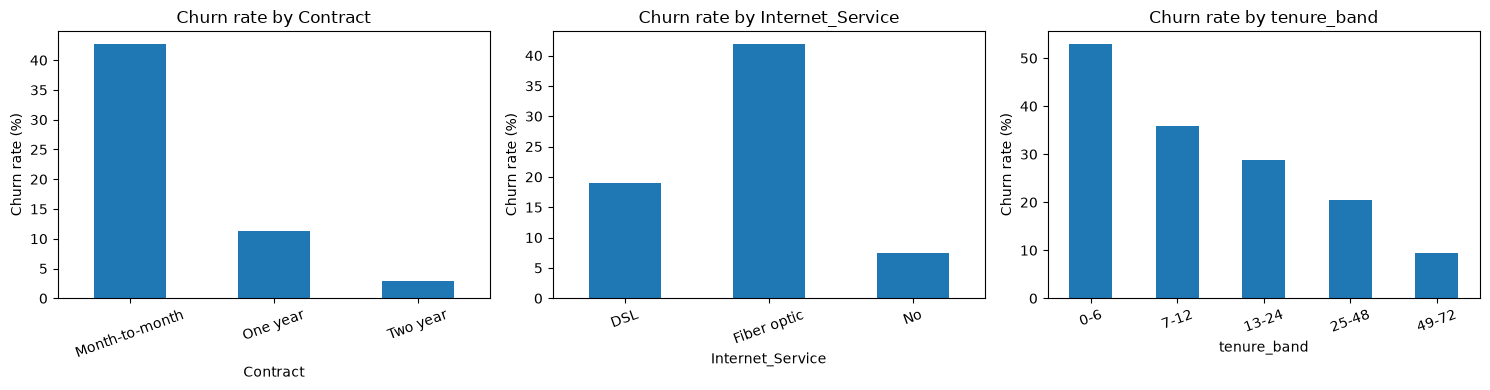

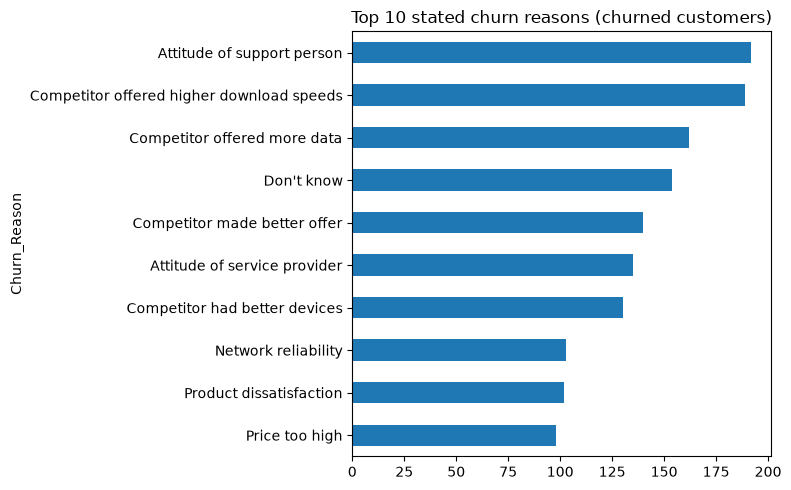

In [19]:
eda = X.assign(churned=y.values)
eda["tenure_band"] = pd.cut(eda["Tenure_Months"], [-1, 6, 12, 24, 48, 72],
                            labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Contract", "Internet_Service", "tenure_band"]):
    eda.groupby(col, observed=True)["churned"].mean().mul(100).plot.bar(ax=ax, rot=20)
    ax.set_ylabel("Churn rate (%)")
    ax.set_title(f"Churn rate by {col}")
plt.tight_layout()
plt.savefig(OUT_DIR / "eda_churn_rates.png", dpi=150)
plt.show()

top_reasons = reasons.value_counts().head(10).sort_values()
top_reasons.plot.barh(figsize=(8, 5), title="Top 10 stated churn reasons (churned customers)")
plt.tight_layout()
plt.savefig(OUT_DIR / "churn_reasons.png", dpi=150)
plt.show()

## 5. Train / test split (stratified) - test set is untouched until the end

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)


def make_pipeline(model):
    """Preprocessing lives INSIDE the pipeline so CV never leaks test-fold info."""
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", StandardScaler(), num_cols),
        ("bin", "passthrough", passthrough_cols),
    ])
    return Pipeline([("pre", pre), ("model", model)])

## 6. Models: baseline -> tree ensembles, with light tuning for boosting

In [21]:
gb_search = RandomizedSearchCV(
    make_pipeline(HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
    param_distributions={
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_depth": [2, 3, 4],
        "model__max_iter": [100, 200, 300],
        "model__min_samples_leaf": [20, 50, 100],
        "model__l2_regularization": [0, 1, 10],
    },
    n_iter=20, scoring="average_precision", cv=cv,
    random_state=RANDOM_STATE, n_jobs=-1,
)
gb_search.fit(X_train, y_train)
print("Best GB params:", gb_search.best_params_)

models = {
    "Logistic Regression": make_pipeline(LogisticRegression(max_iter=2000)),
    "Random Forest": make_pipeline(RandomForestClassifier(
        n_estimators=400, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1)),
    "Gradient Boosting (tuned)": gb_search.best_estimator_,
}

rows = []
for name, model in models.items():
    cv_auc = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc").mean()
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    rows.append({
        "model": name,
        "cv_roc_auc": round(cv_auc, 3),
        "test_roc_auc": round(roc_auc_score(y_test, proba), 3),
        "test_pr_auc": round(average_precision_score(y_test, proba), 3),
    })
results = pd.DataFrame(rows).set_index("model")
print("\n", results)
print(f"(PR-AUC baseline from random guessing = churn rate = {y_test.mean():.3f})")
results.to_csv(OUT_DIR / "model_comparison.csv")

best_name = results["test_pr_auc"].idxmax()
best = models[best_name]
print("\nBest model by PR-AUC:", best_name)

Best GB params: {'model__min_samples_leaf': 100, 'model__max_iter': 100, 'model__max_depth': 3, 'model__learning_rate': 0.1, 'model__l2_regularization': 10}

                            cv_roc_auc  test_roc_auc  test_pr_auc
model                                                           
Logistic Regression             0.860         0.849        0.640
Random Forest                   0.858         0.854        0.664
Gradient Boosting (tuned)       0.864         0.857        0.670
(PR-AUC baseline from random guessing = churn rate = 0.265)

Best model by PR-AUC: Gradient Boosting (tuned)


## 7. ROC / PR curves

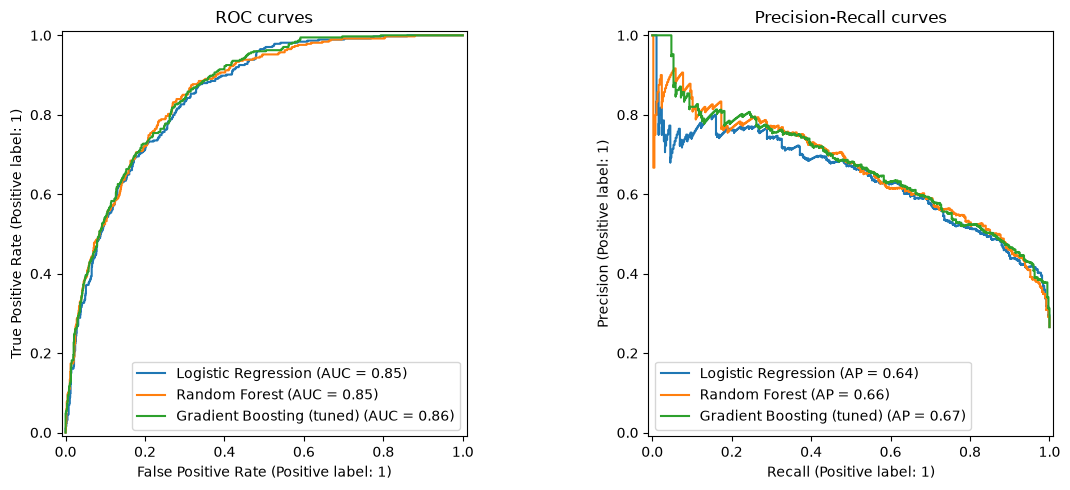

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=axes[0], name=name)
    PrecisionRecallDisplay.from_estimator(model, X_test, y_test, ax=axes[1], name=name)
axes[0].set_title("ROC curves")
axes[1].set_title("Precision-Recall curves")
plt.tight_layout()
plt.savefig(OUT_DIR / "roc_pr_curves.png", dpi=150)
plt.show()

## 8. Business-driven threshold (chosen on TRAIN out-of-fold predictions only)


Chosen threshold: 0.36
Test precision: 0.577 | recall: 0.725
Net benefit (test set, 1409 customers): model-targeted $36,277 vs contact-everyone $-14,746 vs do-nothing $0


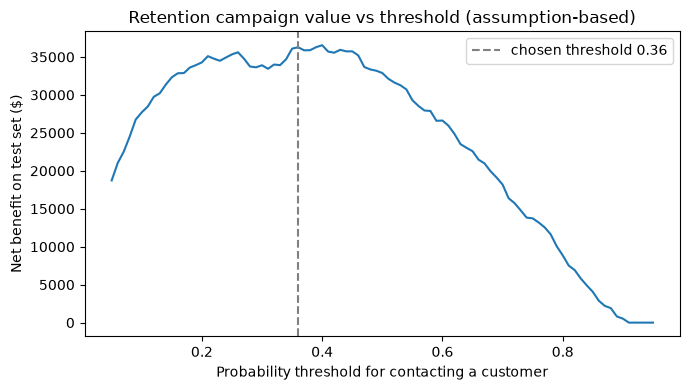

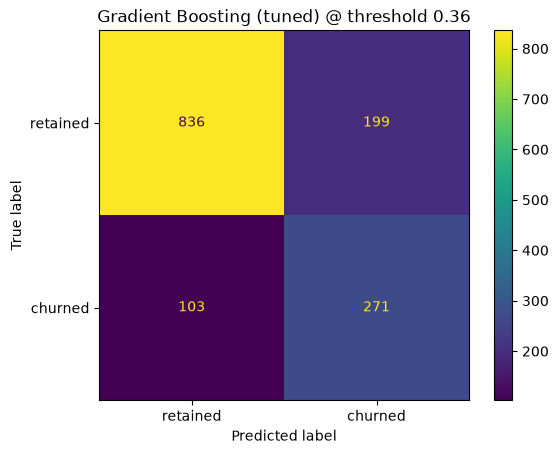

In [23]:
# Contacting a customer costs OFFER_COST. If they were going to churn we save
# SAVE_RATE of their annual revenue. Pick the threshold with the best net benefit.
def net_benefit(y_true, proba, annual_value, threshold):
    contact = proba >= threshold
    gain = np.where(y_true == 1, SAVE_RATE * annual_value, 0.0) - OFFER_COST
    return gain[contact].sum()


train_value = (X_train["Monthly_Charges"] * 12).values
oof_train = cross_val_predict(best, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
thresholds = np.linspace(0.05, 0.95, 91)
train_nb = [net_benefit(y_train.values, oof_train, train_value, t) for t in thresholds]
THRESHOLD = float(thresholds[int(np.argmax(train_nb))])
print(f"\nChosen threshold: {THRESHOLD:.2f}")

proba_test = best.predict_proba(X_test)[:, 1]
test_value = (X_test["Monthly_Charges"] * 12).values
pred_test = (proba_test >= THRESHOLD).astype(int)

nb_model = net_benefit(y_test.values, proba_test, test_value, THRESHOLD)
nb_all = net_benefit(y_test.values, np.ones(len(y_test)), test_value, 0.5)  # contact everyone
print(f"Test precision: {precision_score(y_test, pred_test):.3f} | "
      f"recall: {recall_score(y_test, pred_test):.3f}")
print(f"Net benefit (test set, {len(y_test)} customers): "
      f"model-targeted ${nb_model:,.0f} vs contact-everyone ${nb_all:,.0f} vs do-nothing $0")

plt.figure(figsize=(7, 4))
test_nb_curve = [net_benefit(y_test.values, proba_test, test_value, t) for t in thresholds]
plt.plot(thresholds, test_nb_curve)
plt.axvline(THRESHOLD, ls="--", c="grey", label=f"chosen threshold {THRESHOLD:.2f}")
plt.xlabel("Probability threshold for contacting a customer")
plt.ylabel("Net benefit on test set ($)")
plt.title("Retention campaign value vs threshold (assumption-based)")
plt.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "net_benefit_curve.png", dpi=150)
plt.show()

ConfusionMatrixDisplay.from_predictions(
    y_test, pred_test, display_labels=["retained", "churned"])
plt.title(f"{best_name} @ threshold {THRESHOLD:.2f}")
plt.savefig(OUT_DIR / "confusion_matrix.png", dpi=150)
plt.show()

## 9. What drives churn? (permutation importance on the raw input columns)

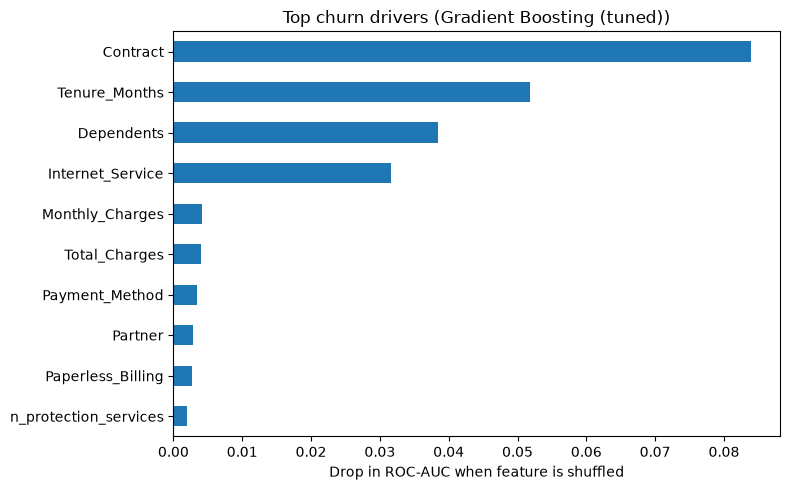

Top drivers:
 Contract                 0.0839
Tenure_Months            0.0519
Dependents               0.0384
Internet_Service         0.0317
Monthly_Charges          0.0042
Total_Charges            0.0040
Payment_Method           0.0034
Partner                  0.0029
Paperless_Billing        0.0027
n_protection_services    0.0019
dtype: float64

Lowest odds ratios (protective):
 bin__Dependents             0.20
cat__Internet_Service_No    0.32
cat__Contract_Two year      0.39
num__Tenure_Months          0.44
bin__Phone_Service          0.63
dtype: float64
Highest odds ratios (risk):
 bin__Paperless_Billing               1.43
bin__Multiple_Lines                  1.44
cat__Contract_Month-to-month         1.66
bin__is_new_customer                 1.70
cat__Internet_Service_Fiber optic    2.02
dtype: float64


In [24]:
perm = permutation_importance(best, X_test, y_test, scoring="roc_auc",
                              n_repeats=15, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X.columns).sort_values()
imp.tail(10).plot.barh(figsize=(8, 5),
                       title=f"Top churn drivers ({best_name})")
plt.xlabel("Drop in ROC-AUC when feature is shuffled")
plt.tight_layout()
plt.savefig(OUT_DIR / "feature_importance.png", dpi=150)
plt.show()
print("Top drivers:\n", imp.sort_values(ascending=False).head(10).round(4))

# Direction of effect from the interpretable baseline (odds ratios)
lr = models["Logistic Regression"]
names = lr.named_steps["pre"].get_feature_names_out()
odds = pd.Series(np.exp(lr.named_steps["model"].coef_[0]), index=names).sort_values()
print("\nLowest odds ratios (protective):\n", odds.head(5).round(2))
print("Highest odds ratios (risk):\n", odds.tail(5).round(2))

## 10. Decile / lift analysis on the test set

In [25]:
scored = pd.DataFrame({"churned": y_test.values, "proba": proba_test,
                       "annual_revenue": test_value}).sort_values("proba", ascending=False)
scored["risk_decile"] = pd.qcut(np.arange(len(scored)), 10, labels=False) + 1  # 1 = riskiest
base_rate = scored["churned"].mean()
decile = scored.groupby("risk_decile").agg(
    customers=("churned", "size"), churners=("churned", "sum"))
decile["churn_rate"] = decile["churners"] / decile["customers"]
decile["lift"] = decile["churn_rate"] / base_rate
decile["cum_churners_captured"] = decile["churners"].cumsum() / decile["churners"].sum()
print("\nDecile analysis (decile 1 = highest predicted risk):\n", decile.round(3))
decile.to_csv(OUT_DIR / "decile_analysis.csv")

top20 = decile.loc[[1, 2]]
print(f"\nTop 20% riskiest customers capture "
      f"{top20['churners'].sum() / decile['churners'].sum():.0%} of all churners; "
      f"top-decile lift = {decile.loc[1, 'lift']:.2f}x")


Decile analysis (decile 1 = highest predicted risk):
              customers  churners  churn_rate   lift  cum_churners_captured
risk_decile                                                               
1                  141       109       0.773  2.912                  0.291
2                  141        81       0.574  2.164                  0.508
3                  141        62       0.440  1.657                  0.674
4                  141        41       0.291  1.095                  0.783
5                  141        41       0.291  1.095                  0.893
6                  140        24       0.171  0.646                  0.957
7                  141        14       0.099  0.374                  0.995
8                  141         1       0.007  0.027                  0.997
9                  141         1       0.007  0.027                  1.000
10                 141         0       0.000  0.000                  1.000

Top 20% riskiest customers capture 51% of al

## 11. Honest scores for ALL customers (out-of-fold) -> Power BI

In [26]:
all_proba = cross_val_predict(best, X, y, cv=cv, method="predict_proba")[:, 1]
export = pd.DataFrame({
    "CustomerID": ids,
    "churn_probability": all_proba.round(4),
    "predicted_churn": (all_proba >= THRESHOLD).astype(int),
    "risk_band": pd.cut(all_proba, [0, THRESHOLD / 2, THRESHOLD, 1.0],
                        labels=["Low", "Medium", "High"], include_lowest=True),
    "actual_churned": y,
    "Contract": X["Contract"],
    "Internet_Service": X["Internet_Service"],
    "Tenure_Months": X["Tenure_Months"],
    "Monthly_Charges": X["Monthly_Charges"],
    "annual_revenue": (X["Monthly_Charges"] * 12).round(2),
    "stated_churn_reason": reasons,
})
export.to_csv(OUT_DIR / "customer_churn_scores.csv", index=False)

# Save the fitted model for reuse
joblib.dump(best, OUT_DIR / "best_churn_model.joblib")
print("\nSaved outputs to", OUT_DIR.resolve())


Saved outputs to C:\Users\Asus\OneDrive\Documents\Projects\Churn Prediction\outputs
